<a href="https://colab.research.google.com/github/Shawntribuce1234/Problem-Set-4/blob/main/ps4_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [ ]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [ ]:
# Store characteristics
floor_area = rng.uniform(1000, 20000, N_STORES)
foot_traffic = rng.integers(100, 2000, N_STORES)
median_income = rng.normal(65000, 15000, N_STORES).clip(25000, 150000)
years_open = rng.integers(1, 31, N_STORES)

# Irrelevant predictors
noise_1 = rng.normal(0, 1, N_STORES)
noise_2 = rng.normal(0, 1, N_STORES)
noise_3 = rng.normal(0, 1, N_STORES)

# Nearly a linear combination of floor area and foot traffic
store_activity = 0.1 * floor_area + 2 * foot_traffic + rng.normal(0, 10, N_STORES)

# Revenue increases with store size but at a decreasing rate
true_revenue = (
    10000
    + 500 * np.sqrt(floor_area)
    + 75 * foot_traffic
    + 0.3 * median_income
    + 1000 * years_open
)

# Larger stores have more variation in revenue
revenue_noise = rng.normal(0, 5000 + 2 * floor_area, N_STORES)
revenue = true_revenue + revenue_noise

# Combine into a DataFrame
stores = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "noise_1": noise_1,
    "noise_2": noise_2,
    "noise_3": noise_3,
    "store_activity": store_activity,
    "revenue": revenue
})

stores.head()

,floor_area,foot_traffic,median_income,years_open,noise_1,noise_2,noise_3,store_activity,revenue
0,15705.165,122,83719.250,10,-0.085,-1.454,-1.340,1810.970,101358.140
1,9338.690,673,61212.240,20,-1.600,-1.262,0.770,2255.477,209540.882
2,17313.360,1079,70451.815,20,-0.762,0.029,-1.893,3894.380,219879.637
3,14249.993,1845,28851.171,18,0.149,1.029,0.217,5108.009,219179.710
4,2789.370,1502,47654.785,3,0.366,-2.214,1.575,3283.363,171278.046


*The data-generating process, recorded: every predictor and the true revenue equation.*

### Step 1.2: Fit it the way they did (12 pts)

In [ ]:
X = stores.drop(columns="revenue")
y = stores["revenue"]

X = sm.add_constant(X)

ols_full = sm.OLS(y, X).fit()

print("Full dataset R^2:", ols_full.rsquared)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ols_split = sm.OLS(y_train, X_train).fit()

train_r2 = ols_split.rsquared
test_r2 = r2_score(y_test, ols_split.predict(X_test))

print("Training R^2:", train_r2)
print("Test R^2:", test_r2)
print("Gap:", train_r2 - test_r2)

Full dataset R^2: 0.7207942617331777
Training R^2: 0.7307542340887454
Test R^2: 0.6864897833593708
Gap: 0.04426445072937457


*Your answer here.*
My OLS model had an R^2 of 0.7208 on the full dataset, translating to it  explaining about 72.1% of the variation in revenue. After splitting the data training R^2 was 0.7308 and test R^2 was 0.6865 leaving a gap of 0.0443 which could be due to some overfitting, but the model still performs fairly similar on unseen data.

### Step 1.3: Say what R-squared is (8 pts)

*Your answer here.*
In-sample R^2 cannot decrease when we add another predictor because OLS can always assign that predictor a coefficient of zero if it doesn't improve the model. So the R^2 will either increase or stay the same, even if the new variable is just noise. Because of this I wouldnt use R^2 alone to choose between models since it can reward unnecessary predictors. Adjusted R^2 is much more useful because it penalizes adding predictors that don't improve the fit enough.

In [ ]:
# Original model
X_original = sm.add_constant(stores.drop(columns="revenue"))
y = stores["revenue"]

model_original = sm.OLS(y, X_original).fit()

# Add three irrelevant predictors
stores_noise = stores.copy()

for i in range(1, 4):
    stores_noise[f"extra_noise_{i}"] = rng.normal(0, 1, len(stores_noise))

# Fit the expanded model
X_noise = sm.add_constant(stores_noise.drop(columns="revenue"))
model_noise = sm.OLS(y, X_noise).fit()

# Compare R-squared and adjusted R-squared
print("Original R^2:", model_original.rsquared)
print("With noise R^2:", model_noise.rsquared)

print("Original R^2 adjusted:", model_original.rsquared_adj)
print("With noise R^2 adjusted:", model_noise.rsquared_adj)

Original R^2: 0.7207942617331777
With noise R^2: 0.72123408098332
Original adjusted R^2: 0.7150816123568745
With noise adjusted R^2: 0.7133309234854244


Results: After adding three random noise predictors my R^2 increased slightly from 0.7208 to 0.7212, even though these variables had no real relationship with revenue. However my adjusted R^2 decreased from 0.7151 to 0.7133 which proves my idea of why I wouldnt use R^2 alone to choose between models, since it can increase just by adding unnecessary predictors. Adjusted R^2 accounts for the number of predictors and shows that the extra variables weren't worth including.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

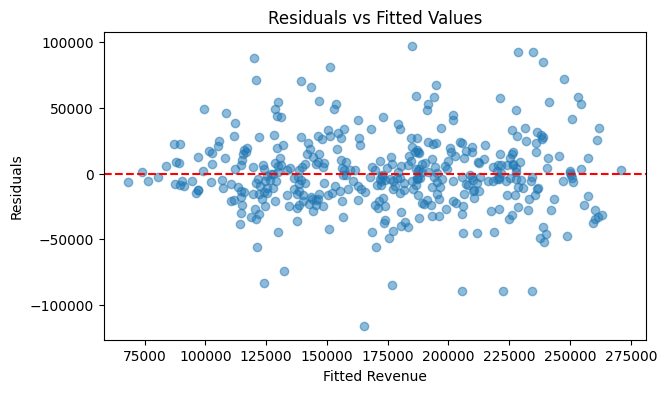

In [ ]:
residuals = ols_full.resid
fitted = ols_full.fittedvalues

plt.figure(figsize=(7, 4))
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted Revenue")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

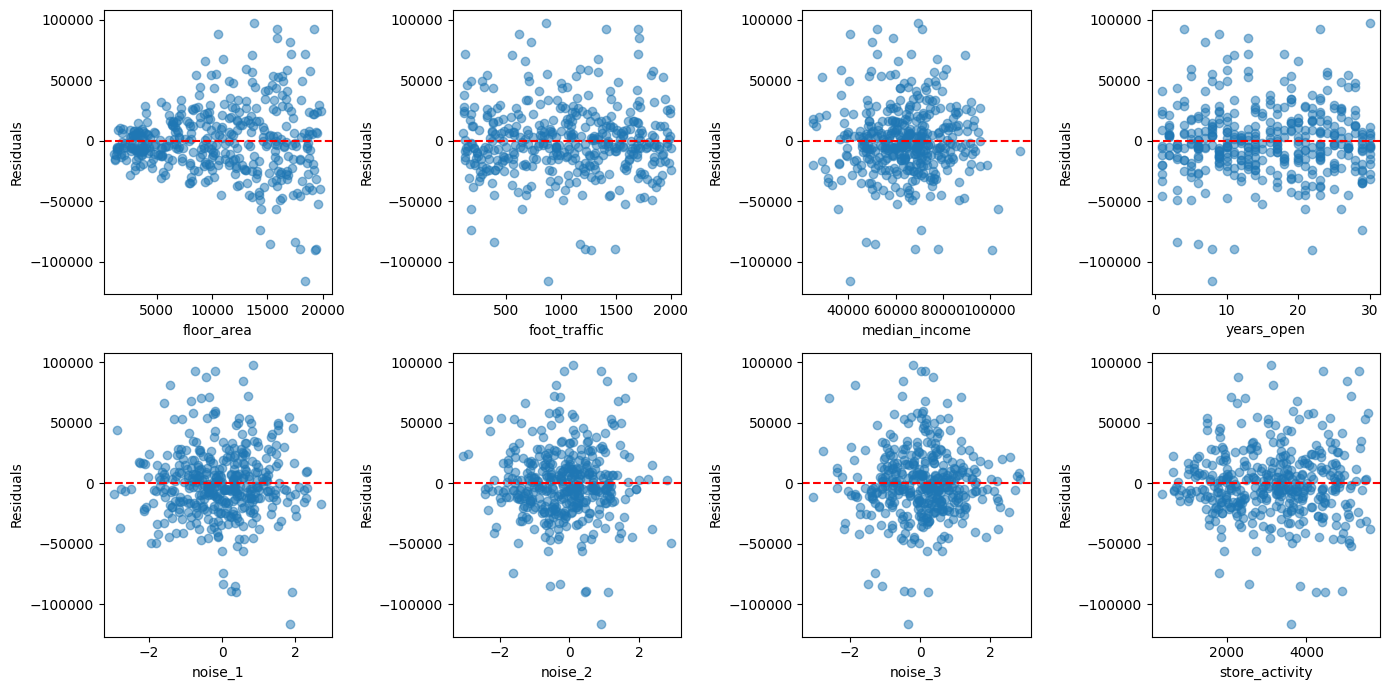

In [ ]:
predictors = stores.drop(columns="revenue").columns

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, col in zip(axes.flat, predictors):
    ax.scatter(stores[col], residuals, alpha=0.5)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel(col)
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

*Your answer here.*
1. My residual plots show that larger stores have a much wider spread of errors than smaller ones. This violates the constant variance assumption but it doesnt automatically bias my OLS coefficient estimates, instead it makes the usual standard errors unreliable, so my confidence intervals and hypothesis tests might be inaccurate.

2. My floor area residual plot shows a slightly curved pattern, which means the linear model isnt fully capturing how revenue changes with store size. This violates the assumption that the conditional mean is correctly specified. As a result my estimated coefficients can misrepresent the true relationship, and the usual standard errors dont account for that model misspecification.

### Step 2.2: The over-forecast on big stores (15 pts)

In [ ]:
diagnostics = stores.copy()

diagnostics["predicted"] = ols_full.fittedvalues
diagnostics["forecast_error"] = diagnostics["predicted"] - diagnostics["revenue"]

# Group stores into four size categories
diagnostics["size_group"] = pd.qcut(
    diagnostics["floor_area"], 4,
    labels=["Small", "Medium", "Large", "Very Large"]
)

# Calculate average errors for each group
size_errors = diagnostics.groupby(
    "size_group", observed=True
).agg(
    stores=("revenue", "size"),
    mean_error=("forecast_error", "mean"),
    mean_absolute_error=("forecast_error", lambda x: x.abs().mean()),
    mean_revenue=("revenue", "mean")
)

print(size_errors.round(2))

            stores  mean_error  mean_absolute_error  mean_revenue
size_group                                                       
Small          100     3695.05              9338.64     151649.95
Medium         100    -3136.83             17721.16     169946.19
Large          100    -2383.47             25564.14     187571.02
Very Large     100     1825.25             31072.56     188506.63


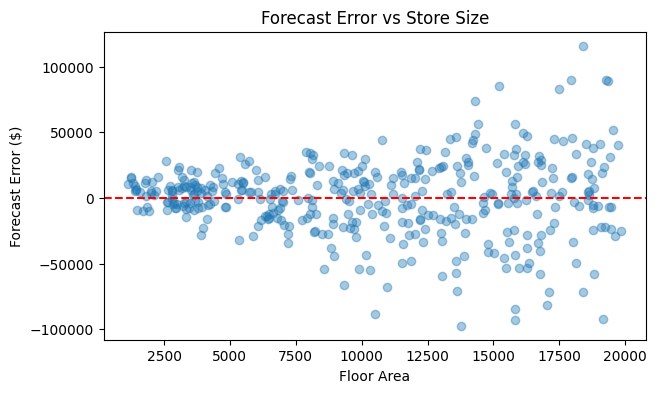

In [ ]:
plt.figure(figsize=(7, 4))

plt.scatter(
    diagnostics["floor_area"],
    diagnostics["forecast_error"],
    alpha=0.4
)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Floor Area")
plt.ylabel("Forecast Error ($)")
plt.title("Forecast Error vs Store Size")
plt.show()

In [ ]:

# Use the predictors from the original OLS model
X_vif = sm.add_constant(stores.drop(columns="revenue"))

vif_results = pd.DataFrame({
    "Predictor": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Exclude the intercept and sort by VIF
vif_results = vif_results[
    vif_results["Predictor"] != "const"
].sort_values("VIF", ascending=False)

print(vif_results.round(2))

        Predictor       VIF
8  store_activity  14710.70
2    foot_traffic  11984.65
1      floor_area   2926.45
7         noise_3      1.03
5         noise_1      1.03
4      years_open      1.02
6         noise_2      1.02
3   median_income      1.01


*Your answer here.*
1. Size-related forecasting errors

My results show that forecasting errors get larger as store size increases. The mean absolute error went from $9,338.64 for small stores to $31,072.56 for very large stores. However, the model only over-forecasted the largest stores by an average of $1,825.25, so the bigger issue appears to be increasing error rather than consistent over-forecasting.

2. My VIF results showed extremely high values for store activity (14,710.70), foot traffic (11,984.65), and floor area (2,926.45). This makes sense because I created store activity using the other two predictors. High VIF makes individual coefficient estimates less precise and increases their standard errors making it harder to determine each variable's separate effect. However,multicollinearity doesn't automatically bias OLS coefficients or make the model's predictions inaccurate so I wouldnt remove a variable just because it has a high VIF.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

In [ ]:
# Same split for every model
train, test = train_test_split(
    stores, test_size=0.2, random_state=42
)

predictors = [
    "floor_area", "foot_traffic", "median_income",
    "years_open", "noise_1", "noise_2",
    "noise_3", "store_activity"
]

results = []

# Models with 1 through 8 predictors
for n in range(1, 9):
    cols = predictors[:n]

    model = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )

    model.fit(train[cols], train["revenue"])

    results.append({
        "complexity": len(cols),
        "model": f"{n} predictors",
        "train_mse": mean_squared_error(
            train["revenue"], model.predict(train[cols])
        ),
        "test_mse": mean_squared_error(
            test["revenue"], model.predict(test[cols])
        )
    })

# Models with polynomial terms and interactions
for degree in [2, 3]:
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(train[predictors], train["revenue"])

    results.append({
        "complexity": model.named_steps["polynomialfeatures"].n_output_features_,
        "model": f"Degree {degree}",
        "train_mse": mean_squared_error(
            train["revenue"], model.predict(train[predictors])
        ),
        "test_mse": mean_squared_error(
            test["revenue"], model.predict(test[predictors])
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(2).to_string(index=False))

 complexity        model  train_mse  test_mse
          1 1 predictors  2.526e+09 3.681e+09
          2 2 predictors  8.545e+08 1.266e+09
          3 3 predictors  8.234e+08 1.287e+09
          4 4 predictors  7.402e+08 1.225e+09
          5 5 predictors  7.374e+08 1.236e+09
          6 6 predictors  7.309e+08 1.251e+09
          7 7 predictors  7.306e+08 1.245e+09
          8 8 predictors  7.297e+08 1.231e+09
         44     Degree 2  6.508e+08 1.347e+09
        164     Degree 3  3.078e+08 2.544e+09


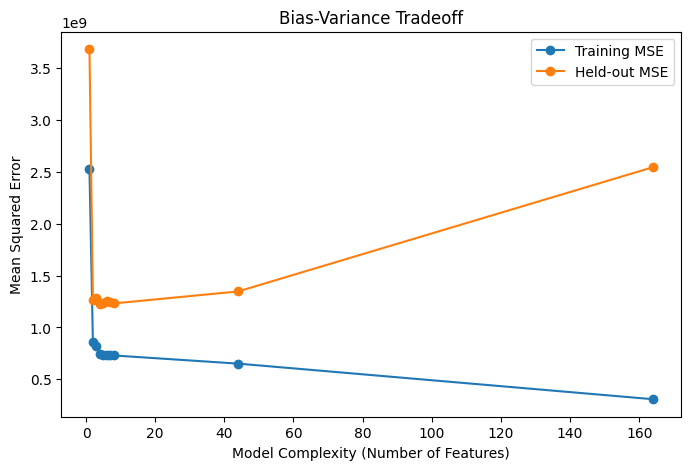

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(results_df["complexity"], results_df["train_mse"],
         marker="o", label="Training MSE")

plt.plot(results_df["complexity"], results_df["test_mse"],
         marker="o", label="Held-out MSE")

plt.xlabel("Model Complexity (Number of Features)")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Tradeoff")
plt.legend()
plt.show()

In [ ]:
best = results_df.loc[results_df["test_mse"].idxmin()]

print("Lowest held-out MSE:", best["test_mse"])
print("Best model:", best["model"])
print("Model complexity:", best["complexity"])

Lowest held-out MSE: 1224790803.17426
Best model: 4 predictors
Model complexity: 4



My held-out MSE was lowest at 4 predictors, with an error of about 1.225 billion. Adding predictors before generally reduced error because the simpler models had higher bias and were underfitting the data.

After 4 predictors the held-out error generally increased while training error continued decreasing. So adding more complexity increased variance and caused overfitting. The degree 3 polynomial was the clearest example, with held-out MSE increasing to 2.544 billion while training MSE dropped to about 308 million.Overall, the model with 4 predictors gave me the best balance between bias and variance among the models I tested.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [ ]:
X = stores.drop(columns="revenue")
y = stores["revenue"]

predictors = list(X.columns)

# Define the same candidate models from Step 3.1
models = {}

for n in range(1, 9):
    models[f"{n} predictors"] = (
        predictors[:n],
        make_pipeline(StandardScaler(), LinearRegression())
    )

for degree in [2, 3]:
    models[f"Degree {degree}"] = (
        predictors,
        make_pipeline(
            StandardScaler(),
            PolynomialFeatures(degree=degree, include_bias=False),
            LinearRegression()
        )
    )

# Inner folds choose the model; outer folds evaluate it
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=123)

outer_errors = []
chosen_models = []

for train_idx, test_idx in outer_cv.split(X):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    cv_errors = {}

    # Compare candidates using only the outer training data
    for name, (cols, model) in models.items():
        scores = cross_val_score(
            model, X_train[cols], y_train,
            cv=inner_cv,
            scoring="neg_mean_squared_error"
        )
        cv_errors[name] = -scores.mean()

    # Choose the model with the lowest inner CV error
    best_name = min(cv_errors, key=cv_errors.get)
    chosen_models.append(best_name)

    # Evaluate it on the untouched outer test fold
    cols, model = models[best_name]
    model.fit(X_train[cols], y_train)

    predictions = model.predict(X_test[cols])
    outer_errors.append(mean_squared_error(y_test, predictions))

# Average error across the five outer folds
outer_errors = np.array(outer_errors)

mean_error = outer_errors.mean()
se = stats.sem(outer_errors)

ci = stats.t.interval(
    0.95,
    df=len(outer_errors) - 1,
    loc=mean_error,
    scale=se
)

print("Nested CV MSE:", mean_error)
print("Approximate 95% interval:", ci)
print("Models chosen:", chosen_models)

Nested CV MSE: 869421921.7770474
Approximate 95% interval: (np.float64(629691728.5494868), np.float64(1109152115.0046082))
Models chosen: ['4 predictors', '8 predictors', '4 predictors', '4 predictors', '4 predictors']


In [ ]:
final_cv_errors = {}

for name, (cols, model) in models.items():
    scores = cross_val_score(
        model, X[cols], y,
        cv=inner_cv,
        scoring="neg_mean_squared_error"
    )
    final_cv_errors[name] = -scores.mean()

best_model = min(final_cv_errors, key=final_cv_errors.get)

print("Selected model:", best_model)
print("Lowest regular CV MSE:", final_cv_errors[best_model])
print("Nested CV MSE:", mean_error)
print("Approximate 95% interval:", ci)

Selected model: 4 predictors
Lowest regular CV MSE: 861080618.0832402
Nested CV MSE: 869421921.7770474
Approximate 95% interval: (np.float64(629691728.5494868), np.float64(1109152115.0046082))


I used 5-fold cross-validation to select the four predictor model, which had a CV MSE of about 861.1 million. Nested cross-validation estimated a slightly higher MSE of 869.4 million, with an approximate 95% interval of 629.7 million to 1.109 billion.

The problem with regular cross-validation is that I used the same CV results to choose the best model and estimate its performance, which can make the error look better than it actually is. Nested CV helps fix this by using inner folds to select the model and separate outer folds to evaluate it. The higher nested CV error suggests that my original CV estimate had a little false accuracy, but the difference was fairly small.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

Act as a machine learning engineer helping me diagnose a store revenue regression model for a data science assignment.

I have a simulated dataset of 400 stores with predictors including floor area, foot traffic, median income, years open, and several irrelevant and highly correlated variables.

In Phase 3, I used cross-validation to select a linear regression model with four predictors: floor area, foot traffic, median income, and years open.

Write Python code using scikit-learn, NumPy, and Matplotlib that:

1. Creates a learning curve using my existing X and y variables and the four predictors selected in Phase 3.
2. Uses 5-fold cross-validation and calculates training and validation mean squared error at different training sample sizes.
3. Plots both learning curves on one graph, including shaded bands showing variability across folds.
4. Includes comments explaining how the gap between the curves indicates variance and how the level they converge toward indicates bias or other model limitations.
5. Prints the final training MSE, validation MSE, and their difference.
6. Explains whether collecting more stores or improving the model's features would likely help more.

Do not generate example data or replace my existing X and y variables. Keep the code straightforward and explain how I can compare the results with my Phase 3 findings.

AI Transcript — ChatGPT (GPT-6), November 18, 2026

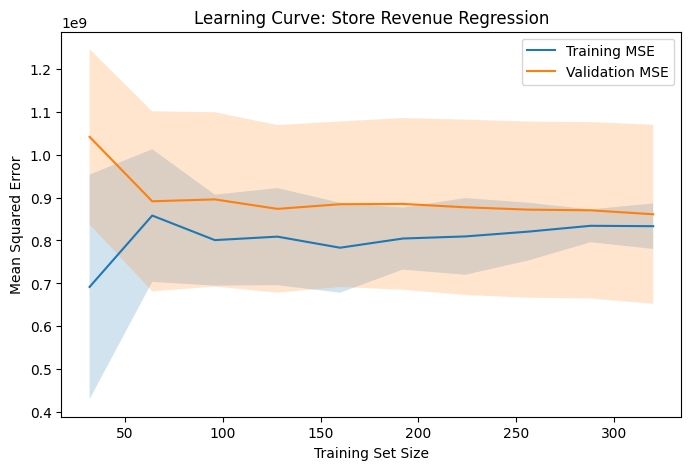

Final training MSE: 833300570.3489177
Final validation MSE: 861080618.0832403
Final gap: 27780047.734322548


In [ ]:
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Use the four predictors selected in Phase 3
features = ["floor_area", "foot_traffic", "median_income", "years_open"]
X_model = stores[features]
y_model = stores["revenue"]

# Create the model
model = make_pipeline(StandardScaler(), LinearRegression())

# Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Calculate training and validation errors
sizes, train_scores, val_scores = learning_curve(
    model,
    X_model,
    y_model,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42
)

# Convert scores to positive MSE
train_mse = -train_scores
val_mse = -val_scores

# Average across folds
train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

# Calculate variability
train_std = train_mse.std(axis=1)
val_std = val_mse.std(axis=1)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, marker="o", label="Training MSE")
plt.plot(sizes, val_mean, marker="o", label="Validation MSE")

plt.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)

plt.xlabel("Number of Training Stores")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve: Store Revenue")
plt.legend()
plt.show()

# Print final results
print("Final training MSE:", train_mean[-1])
print("Final validation MSE:", val_mean[-1])
print("Final gap:", val_mean[-1] - train_mean[-1])

I'm working on a machine learning project predicting store revenue. I already have my predictor variables stored in X and my revenue outcome stored in y.

Using scikit-learn, write simple Python code that standardizes my predictors, uses SelectKBest with f_regression to select the four best features, and evaluates a LinearRegression model using 5-fold cross-validation with R² as the scoring metric.

Print the average validation R² rounded to two decimal places. Keep the code short, reuse my existing X and y, and don't generate example data.

AI Transcript — ChatGPT (GPT-6), November 18, 2026

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=4).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.70


### Verification and Conclusion

I ran the AI-generated learning curve using the four predictors selected in Phase 3. My final training MSE was 833.3 million, while validation MSE was 861.1 million, giving a gap of 27.8 million. The two curves got closer together and started leveling off as I increased the number of stores. This suggests that high variance isn't the main problem anymore. Instead, the model may have some remaining bias or missing relationships that adding more data won't necessarily fix.

This follows the same logic as my Phase 3 findings because the four-predictor model performed better than the more complicated models, and my residual plots showed that OLS missed some of the nonlinear relationship between floor area and revenue. I would prioritize improving the models features or functional form rather than collecting more stores, since the learning curve suggests that additional observations alone may not improve predictions very much.

**Changes I made:** I removed the duplicate learning-curve code and identified a data leakage issue in a separate feature-selection step, where scaling and feature selection were performed before cross-validation.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

a) The problem is SelectKBest because it uses the revenue values from the entire dataset to choose predictors before cross-validation. This could mean that information from the validation folds has already influenced feature selection, making the validation R^2 slighlty falsely accurate. StandardScaler also uses the full dataset, but it doesn't use revenue to calculate the mean and standard deviation. For ordinary OLS with an intercept, rescaling predictors doesnt change the fitted predictions within a given training fold, so it isnt responsible for inflating this score.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Generate 300 pure noise predictors
rng_noise = np.random.default_rng(42)
X_noise = rng_noise.normal(size=(len(stores), 300))
y_noise = stores["revenue"]

# Departing analysts approach
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y_noise)

leaky_scores = cross_val_score(
    LinearRegression(), X_sel, y_noise, cv=5, scoring="r2"
)

# Correct approach
pipeline = make_pipeline(
    StandardScaler(),
    SelectKBest(f_regression, k=20),
    LinearRegression()
)

correct_scores = cross_val_score(
    pipeline, X_noise, y_noise, cv=5, scoring="r2"
)

print("Leaky CV R^2:", leaky_scores.mean())
print("Pipeline CV R^2:", correct_scores.mean())
print("Gap:", leaky_scores.mean() - correct_scores.mean())

Leaky CV R²: 0.06050064578657588
Pipeline CV R²: -0.3746041969460708
Gap: 0.43510484273264666


b)When I tested the model using 300 pure noise predictors, the original code gave me a validation R^2 of about 0.0605 but when I moved scaling and feature selection inside the pipeline, R^2 dropped to -0.3746, resulting in a difference of 0.4351.

The original model appeared to find predictive information in variables that were completely random. The negative R^2 from the corrected pipeline means it performed worse than simply predicting the average revenue of each training fold. The gap is evident that if features are selected before cross-validation it can make a model look much better than it actually is.

c) This is a special case of the selection bias problem from Step 3.2 because both make validation results overly optimistic, but here the problem comes from selecting features before cross-validation rather than choosing the model with the lowest CV error.

### Task 4.3: The handover note (3 pts)



**What the model predicts**

I built a regression model to predict store revenue using floor area, foot traffic, local median income, and years open. These four predictors performed best during cross-validation.

**Expected Error**

Nested cross-validation estimated an MSE of 869.4 million, with an approximate 95% interval of 629.7 million to 1.109 billion.

**Where the model fails**

First, the model struggles with larger stores. Their average absolute error was $31,072.56 compared to $9,338.64 for smaller stores. Also, the model misses the nonlinear relationship between floor area and revenue, which can lead to systematic forecasting errors.

**What I would build next**

I would focus on improving the model rather than collecting more data. My learning curve showed that training and validation errors were getting closer together. I would test a square-root transformation of floor area and use cross-validation to see whether it improves predictions, especially for larger stores.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

Model and date: ChatGPT (GPT-6), November 18, 2026

Prompt:

Act as a machine learning engineer helping me evaluate my store revenue regression model.

I have a dataset of 400 stores, and in Phase 3, cross-validation selected four predictors: floor area, foot traffic, median income, and years open.

Write Python code using scikit-learn, NumPy, and Matplotlib that:

Uses my existing stores dataset without generating new data.

Creates a learning curve using 5-fold cross-validation.

Plots training and validation MSE against training set size, with shaded bands showing variability across folds.

Prints the final training MSE, validation MSE, and the gap between them.

Includes comments explaining how a large gap indicates high variance, while two curves converging at a high error level suggest high bias or missing model structure.

Explains whether collecting more stores or improving the model's features would likely help more.

Keep the code simple, use the four predictors selected in Phase 3, and avoid unnecessary libraries.

Reply:

from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Use the four predictors selected in Phase 3
features = ["floor_area", "foot_traffic", "median_income", "years_open"]
X_model = stores[features]
y_model = stores["revenue"]

# Create the model
model = make_pipeline(StandardScaler(), LinearRegression())

# Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Calculate training and validation errors
sizes, train_scores, val_scores = learning_curve(
    model,
    X_model,
    y_model,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42
)

# Convert scores to positive MSE
train_mse = -train_scores
val_mse = -val_scores

# Average across folds
train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

# Calculate variability
train_std = train_mse.std(axis=1)
val_std = val_mse.std(axis=1)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(sizes, train_mean, marker="o", label="Training MSE")
plt.plot(sizes, val_mean, marker="o", label="Validation MSE")

plt.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)

plt.xlabel("Number of Training Stores")
plt.ylabel("Mean Squared Error")
plt.title("Learning Curve: Store Revenue")
plt.legend()
plt.show()

# Print final results
print("Final training MSE:", train_mean[-1])
print("Final validation MSE:", val_mean[-1])



AI Transcript 2 — Feature Selection and Validation

Model and date: ChatGPT (GPT-6), November 18, 2026

Prompt:

I'm working on a machine learning project predicting store revenue. I already have my predictor variables stored in X and my revenue outcome stored in y.

Using scikit-learn, write simple Python code that standardizes my predictors, uses SelectKBest with f_regression to select the four best features, and evaluates a LinearRegression model using 5-fold cross-validation with R² as the scoring metric.

Print the average validation R² rounded to two decimal places. Keep the code short, reuse my existing X and y, and don't generate example data.

Reply:

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=4).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.